# MOD_C
## WEEK 1

### Project: Cardiovascular Disease

This notebook continues the cardiovascular disease project developed in Module B.
The Week 1 analysis applies linear regression, polynomial terms, interaction terms,
overfitting checks, and multicollinearity concepts to two cardiovascular datasets:

1. Statlog Heart Disease Dataset
2. Framingham Heart Study Dataset

Because the main disease outcomes in these datasets are binary, ordinary linear regression
will not be used to predict heart disease directly in Week 1. Instead, continuous cardiovascular
measurements will be examined to determine whether nonlinear relationships and interactions
provide additional explanatory value.

In [1]:
from google.colab import files

uploaded = files.upload()

Saving preprocessed_framingham.csv to preprocessed_framingham.csv
Saving preprocessed_heart_disease.csv to preprocessed_heart_disease.csv


In [2]:
import pandas as pd

heart = pd.read_csv("/content/preprocessed_heart_disease.csv")
framingham = pd.read_csv("/content/preprocessed_framingham.csv")

print("Heart Disease:", heart.shape)
print("Framingham:", framingham.shape)

display(heart.head())
display(framingham.head())

Heart Disease: (270, 14)
Framingham: (4238, 16)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [3]:
import os

print(os.listdir("/content"))

['.config', 'preprocessed_framingham.csv', 'preprocessed_heart_disease.csv', 'sample_data']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

heart = pd.read_csv("/content/preprocessed_heart_disease.csv")
framingham = pd.read_csv("/content/preprocessed_framingham.csv")

print("Heart Disease dataset shape:", heart.shape)
print("Framingham dataset shape:", framingham.shape)

Heart Disease dataset shape: (270, 14)
Framingham dataset shape: (4238, 16)


In [5]:
print("HEART DISEASE DATA")
display(heart.head())

print("\nFRAMINGHAM DATA")
display(framingham.head())

HEART DISEASE DATA


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,70,1,3,130,322,0,2,109,0,2.4,1,3,1,1
1,67,0,2,115,564,0,2,160,0,1.6,1,0,3,0
2,57,1,1,124,261,0,0,141,0,0.3,0,0,3,1
3,64,1,3,128,263,0,0,105,1,0.2,1,1,3,0
4,74,0,1,120,269,0,2,121,1,0.2,0,1,1,0



FRAMINGHAM DATA


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [6]:
print("Heart Disease columns:")
print(heart.columns.tolist())

print("\nFramingham columns:")
print(framingham.columns.tolist())

Heart Disease columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Framingham columns:
['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD']


## Dataset 1: Statlog Heart Disease

For the Statlog dataset, I will examine whether age, cholesterol, and resting blood pressure
help explain maximum heart rate (`thalach`).

The initial predictors are:

- `age`
- `chol` = cholesterol
- `trestbps` = resting blood pressure

The continuous outcome variable is:

- `thalach` = maximum heart rate achieved

I will first examine the relationships visually and then compare linear and polynomial regression models.

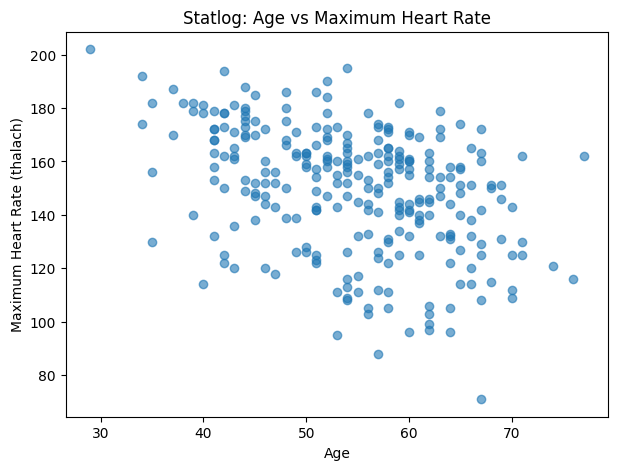

In [7]:
plt.figure(figsize=(7, 5))

plt.scatter(
    heart["age"],
    heart["thalach"],
    alpha=0.6
)

plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate (thalach)")
plt.title("Statlog: Age vs Maximum Heart Rate")

plt.show()

## Dataset 2: Framingham Heart Study

For the Framingham dataset, I will examine whether age, BMI, and total cholesterol
help explain systolic blood pressure (`sysBP`).

The initial predictors are:

- `age`
- `BMI`
- `totChol` = total cholesterol

The continuous outcome variable is:

- `sysBP` = systolic blood pressure

As with the Statlog dataset, I will first examine the relationship visually before comparing
linear and polynomial regression models.

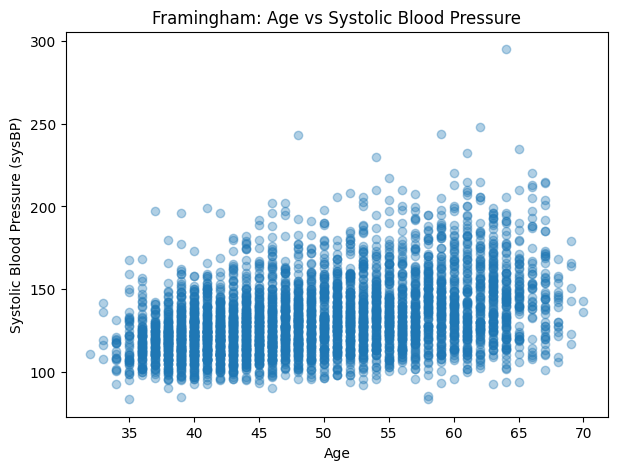

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(
    framingham["age"],
    framingham["sysBP"],
    alpha=0.35
)

plt.xlabel("Age")
plt.ylabel("Systolic Blood Pressure (sysBP)")
plt.title("Framingham: Age vs Systolic Blood Pressure")

plt.show()

## Linear vs Polynomial Regression

A standard linear regression assumes that the relationship between predictors and the outcome
can be represented using straight-line relationships.

Polynomial regression allows curved relationships by adding terms such as:

- \(X^2\)
- \(X^3\)

For example, instead of modeling an outcome using only age, a polynomial model may also include
age squared. This allows the effect of age to change across different age levels.

However, adding too many polynomial terms can cause overfitting. Therefore, I will compare
linear, quadratic, and cubic models using both training and testing performance.

In [9]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

print("Modeling tools loaded successfully.")

Modeling tools loaded successfully.


In [10]:
def compare_polynomial_models(df, predictors, target, dataset_name):

    # Keep only the columns needed for this model
    data = df[predictors + [target]].dropna()

    X = data[predictors]
    y = data[target]

    # Split the data:
    # 80% for training and 20% for testing
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    results = []

    # Degree 1 = normal linear regression
    # Degree 2 = quadratic polynomial regression
    # Degree 3 = cubic polynomial regression
    for degree in [1, 2, 3]:

        model = make_pipeline(
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            ),
            LinearRegression()
        )

        model.fit(X_train, y_train)

        train_predictions = model.predict(X_train)
        test_predictions = model.predict(X_test)

        train_r2 = r2_score(
            y_train,
            train_predictions
        )

        test_r2 = r2_score(
            y_test,
            test_predictions
        )

        test_rmse = np.sqrt(
            mean_squared_error(
                y_test,
                test_predictions
            )
        )

        # 5-fold cross-validation
        cv_scores = -cross_val_score(
            model,
            X,
            y,
            cv=5,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(cv_scores).mean()

        results.append({
            "Polynomial Degree": degree,
            "Training R²": round(train_r2, 3),
            "Testing R²": round(test_r2, 3),
            "Testing RMSE": round(test_rmse, 3),
            "5-Fold CV RMSE": round(cv_rmse, 3)
        })

    results_df = pd.DataFrame(results)

    print(dataset_name)
    display(results_df)

    return results_df

### Statlog Polynomial Model Comparison

The Statlog models compare whether adding nonlinear and interaction terms improves the prediction
of maximum heart rate using age, cholesterol, and resting blood pressure.

In [11]:
heart_results = compare_polynomial_models(
    df=heart,
    predictors=[
        "age",
        "chol",
        "trestbps"
    ],
    target="thalach",
    dataset_name="Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Polynomial Degree,Training R²,Testing R²,Testing RMSE,5-Fold CV RMSE
0,1,0.169,0.153,22.211,21.056
1,2,0.191,0.157,22.158,21.257
2,3,0.217,0.127,22.552,23.876


### Statlog Results Interpretation

The linear model (Degree 1) produced a training R² of 0.169 and a testing R² of 0.153.
This means that the model explained approximately 15.3% of the variation in maximum heart rate
on the unseen test data.

The quadratic model (Degree 2) slightly increased testing R² from 0.153 to 0.157 and slightly
reduced testing RMSE from 22.211 to 22.158. However, its 5-fold cross-validation RMSE increased
from 21.056 to 21.257. This suggests that the small improvement on the single test split may not
represent a meaningful overall improvement.

The cubic model (Degree 3) increased training R² to 0.217 but reduced testing R² to 0.127.
Its cross-validation RMSE also increased substantially to 23.876. This pattern suggests overfitting:
the more complex model fits the training data better but performs worse on unseen data.

Overall, polynomial terms provided little improvement for the Statlog dataset. The simpler linear
model appears more stable and generalizable than the higher-degree models.

### Framingham Polynomial Model Comparison

The Framingham models compare whether adding nonlinear and interaction terms improves the prediction
of systolic blood pressure using age, BMI, and total cholesterol.

In [12]:
framingham_results = compare_polynomial_models(
    df=framingham,
    predictors=[
        "age",
        "BMI",
        "totChol"
    ],
    target="sysBP",
    dataset_name="Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Polynomial Degree,Training R²,Testing R²,Testing RMSE,5-Fold CV RMSE
0,1,0.246,0.204,19.363,19.248
1,2,0.251,0.198,19.444,19.245
2,3,0.252,0.193,19.507,19.288


### Framingham Results Interpretation

The linear model (Degree 1) achieved a training R² of 0.246 and a testing R² of 0.204,
with a testing RMSE of 19.363.

Adding quadratic terms slightly increased training R² to 0.251, but testing R² decreased to 0.198.
The cubic model increased training R² only slightly further to 0.252 while testing R² fell again
to 0.193.

The RMSE values also became slightly worse as model complexity increased. Cross-validation
performance remained very similar between the linear and quadratic models, while the cubic model
performed slightly worse.

These results suggest that polynomial terms add little useful predictive information for systolic
blood pressure in this set of predictors. The linear model is therefore preferable because it performs
at least as well on unseen data while remaining simpler and easier to interpret.

## Comparison of Polynomial Results

Across both datasets, higher-degree polynomial models improved training performance more than
testing performance.

For Statlog, the cubic model showed the clearest evidence of overfitting. For Framingham,
additional polynomial complexity produced almost no benefit and slightly reduced test performance.

Therefore, these results suggest that the selected cardiovascular relationships are largely better
represented by simpler models than by high-degree polynomial models.

## Interaction Terms

Interaction terms test whether the relationship between one predictor and the outcome changes
depending on the value of another predictor.

For example, an interaction between age and cholesterol asks whether the relationship involving age
changes depending on cholesterol level.

I will compare a standard linear model with a model containing pairwise interaction terms to determine
whether interactions improve predictive performance.

In [13]:
from sklearn.preprocessing import PolynomialFeatures

def compare_interaction_model(df, predictors, target, dataset_name):

    data = df[predictors + [target]].dropna()

    X = data[predictors]
    y = data[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    # Standard linear regression
    linear_model = LinearRegression()
    linear_model.fit(X_train, y_train)

    linear_train_pred = linear_model.predict(X_train)
    linear_test_pred = linear_model.predict(X_test)

    # Interaction model
    interaction_model = make_pipeline(
        PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False
        ),
        LinearRegression()
    )

    interaction_model.fit(X_train, y_train)

    interaction_train_pred = interaction_model.predict(X_train)
    interaction_test_pred = interaction_model.predict(X_test)

    results = pd.DataFrame({
        "Model": [
            "Linear",
            "Linear + Interactions"
        ],
        "Training R²": [
            r2_score(y_train, linear_train_pred),
            r2_score(y_train, interaction_train_pred)
        ],
        "Testing R²": [
            r2_score(y_test, linear_test_pred),
            r2_score(y_test, interaction_test_pred)
        ],
        "Testing RMSE": [
            np.sqrt(mean_squared_error(y_test, linear_test_pred)),
            np.sqrt(mean_squared_error(y_test, interaction_test_pred))
        ]
    })

    results = results.round(3)

    print(dataset_name)
    display(results)

    return results

### Statlog Interaction Model

In [14]:
heart_interactions = compare_interaction_model(
    df=heart,
    predictors=[
        "age",
        "chol",
        "trestbps"
    ],
    target="thalach",
    dataset_name="Statlog Heart Disease Dataset"
)

Statlog Heart Disease Dataset


,Model,Training R²,Testing R²,Testing RMSE
0,Linear,0.169,0.153,22.211
1,Linear + Interactions,0.189,0.172,21.959


### Framingham Interaction Model

In [15]:
framingham_interactions = compare_interaction_model(
    df=framingham,
    predictors=[
        "age",
        "BMI",
        "totChol"
    ],
    target="sysBP",
    dataset_name="Framingham Heart Study Dataset"
)

Framingham Heart Study Dataset


,Model,Training R²,Testing R²,Testing RMSE
0,Linear,0.246,0.204,19.363
1,Linear + Interactions,0.248,0.201,19.403


### Interaction Features

The following output shows the additional pairwise terms created by the interaction model.

In [16]:
heart_interaction_features = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

heart_interaction_features.fit(
    heart[["age", "chol", "trestbps"]]
)

print("Statlog interaction features:")
print(
    heart_interaction_features.get_feature_names_out(
        ["age", "chol", "trestbps"]
    )
)

Statlog interaction features:
['age' 'chol' 'trestbps' 'age chol' 'age trestbps' 'chol trestbps']


### Statlog Interaction Results Interpretation

Adding pairwise interaction terms produced a modest improvement in the Statlog model.

The standard linear model had a testing R² of 0.153 and a testing RMSE of 22.211.
After adding interaction terms, testing R² increased to 0.172 and testing RMSE decreased
to 21.959.

This suggests that interactions among age, cholesterol, and resting blood pressure contain
some additional information about maximum heart rate beyond the variables considered separately.

However, the improvement is relatively small, so the interaction model should not automatically
be considered substantially better. The added complexity must also be considered alongside
possible multicollinearity.

In [17]:
framingham_interaction_features = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

framingham_interaction_features.fit(
    framingham[["age", "BMI", "totChol"]]
)

print("Framingham interaction features:")
print(
    framingham_interaction_features.get_feature_names_out(
        ["age", "BMI", "totChol"]
    )
)

Framingham interaction features:
['age' 'BMI' 'totChol' 'age BMI' 'age totChol' 'BMI totChol']


### Framingham Interaction Results Interpretation

Adding interaction terms did not improve the Framingham model.

The standard linear model produced a testing R² of 0.204 and a testing RMSE of 19.363.
After adding interactions, testing R² decreased slightly to 0.201 and testing RMSE increased
slightly to 19.403.

Therefore, the interaction terms between age, BMI, and total cholesterol did not provide useful
additional predictive information for systolic blood pressure in this model.

Because the interaction model is more complex without improving test performance, the simpler
linear model is preferable for these predictors.

## Multicollinearity and Variance Inflation Factor (VIF)

Polynomial and interaction terms can introduce multicollinearity because newly created variables
may be strongly related to the original predictors or to one another.

Multicollinearity can make regression coefficients unstable and difficult to interpret.

Variance Inflation Factor (VIF) will be used to evaluate this issue. A VIF near 1 indicates little
multicollinearity, while substantially larger values suggest that a predictor contains information
that overlaps strongly with other predictors.

To reduce unnecessary multicollinearity before generating polynomial and interaction terms, the
predictors will first be mean-centered.

In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("VIF tools loaded successfully.")

VIF tools loaded successfully.


In [19]:
def calculate_vif(dataframe):

    vif_table = pd.DataFrame()

    vif_table["Feature"] = dataframe.columns

    vif_table["VIF"] = [
        variance_inflation_factor(
            dataframe.values,
            i
        )
        for i in range(dataframe.shape[1])
    ]

    return vif_table.round(2)

### Statlog: VIF of Original Predictors

I will first examine multicollinearity among the original Statlog predictors before introducing
polynomial and interaction terms.

In [20]:
heart_base = heart[
    ["age", "chol", "trestbps"]
].dropna()

heart_base_vif = calculate_vif(
    heart_base
)

display(heart_base_vif)

,Feature,VIF
0,age,1.12
1,chol,1.07
2,trestbps,1.10


### Framingham: VIF of Original Predictors

The same VIF analysis will be applied to age, BMI, and total cholesterol in the Framingham dataset.

In [21]:
framingham_base = framingham[
    ["age", "BMI", "totChol"]
].dropna()

framingham_base_vif = calculate_vif(
    framingham_base
)

display(framingham_base_vif)

,Feature,VIF
0,age,1.09
1,BMI,1.03
2,totChol,1.08


### VIF After Adding Polynomial and Interaction Terms

Polynomial regression creates additional terms such as squared predictors and interactions.
Because these terms are mathematically related to the original variables, they can introduce
multicollinearity.

The original predictors are mean-centered before creating second-degree polynomial terms to reduce
unnecessary multicollinearity.

In [22]:
def polynomial_vif(df, predictors):

    data = df[predictors].dropna().copy()

    # Mean-center each predictor
    centered = data - data.mean()

    # Create squared terms and interaction terms
    poly = PolynomialFeatures(
        degree=2,
        include_bias=False
    )

    transformed = poly.fit_transform(centered)

    feature_names = poly.get_feature_names_out(
        predictors
    )

    transformed_df = pd.DataFrame(
        transformed,
        columns=feature_names
    )

    return calculate_vif(
        transformed_df
    )

### Statlog Polynomial VIF

In [23]:
heart_poly_vif = polynomial_vif(
    heart,
    ["age", "chol", "trestbps"]
)

display(heart_poly_vif)

,Feature,VIF
0,age,1.18
1,chol,1.37
2,trestbps,1.38
3,age^2,1.12
4,age chol,1.66
5,age trestbps,1.30
6,chol^2,1.83
7,chol trestbps,1.32
8,trestbps^2,1.48


### Statlog VIF Interpretation

The original Statlog predictors showed very low VIF values, ranging from 1.07 to 1.12,
indicating little multicollinearity among age, cholesterol, and resting blood pressure.

After mean-centering the predictors and adding second-degree polynomial and interaction terms,
the VIF values remained low. The highest VIF was 1.83 for the squared cholesterol term.

These results suggest that the polynomial and interaction terms did not introduce problematic
multicollinearity into the Statlog model. Therefore, the weaker performance of the more complex
models is more likely due to limited predictive benefit and overfitting rather than unstable
relationships among predictors.

### Framingham Polynomial VIF

In [24]:
framingham_poly_vif = polynomial_vif(
    framingham,
    ["age", "BMI", "totChol"]
)

display(framingham_poly_vif)

,Feature,VIF
0,age,1.19
1,BMI,1.32
2,totChol,1.29
3,age^2,1.13
4,age BMI,1.12
5,age totChol,1.11
6,BMI^2,1.32
7,BMI totChol,1.08
8,totChol^2,1.20


### Framingham VIF Interpretation

The original Framingham predictors also showed very low VIF values, ranging from 1.03 to 1.09,
indicating little multicollinearity among age, BMI, and total cholesterol.

After adding mean-centered polynomial and interaction terms, all VIF values remained low, with
the highest value approximately 1.32.

Therefore, multicollinearity does not appear to be a major concern for the Framingham models.
The lack of improvement from polynomial and interaction terms is more likely because these
additional terms do not provide much useful predictive information for systolic blood pressure.

# Week 1 Overall Conclusion

Week 1 examined whether polynomial and interaction terms improved linear regression models
for two cardiovascular datasets.

For the Statlog Heart Disease dataset, age showed a clear negative relationship with maximum
heart rate in the exploratory scatterplot. A quadratic model produced only a very small improvement
over the linear model, while the cubic model showed evidence of overfitting because training R²
increased while testing R² and cross-validation performance became worse. Interaction terms
provided a small improvement, increasing testing R² from 0.153 to 0.172 and reducing RMSE from
22.211 to 21.959.

For the Framingham Heart Study dataset, age showed a positive relationship with systolic blood
pressure. Polynomial terms did not improve testing performance. The linear model achieved a
testing R² of 0.204, while quadratic and cubic models performed slightly worse. Interaction terms
also failed to improve the model, reducing testing R² slightly from 0.204 to 0.201.

VIF analysis showed that multicollinearity was not a major issue in either dataset. All original
and polynomial VIF values remained well below commonly used warning thresholds.

Overall, the results suggest that adding polynomial complexity does not automatically improve a
model. Simpler linear models were more stable for both datasets, although the Statlog dataset
showed a small benefit from interaction terms. This analysis also demonstrates the importance of
evaluating models using testing performance and cross-validation rather than relying only on
training fit.

## Metrics Used

The main evaluation metrics used were:

- **R²:** Measures how much of the variation in the outcome is explained by the model. Higher values indicate better explanatory performance.
- **RMSE:** Measures the typical size of prediction errors. Lower values indicate better predictive accuracy.
- **5-Fold Cross-Validation RMSE:** Measures how consistently the model performs across multiple subsets of the data and helps detect overfitting.
- **VIF:** Measures multicollinearity among predictors. Higher values indicate stronger redundancy among features.

## AI Use Disclosure

ChatGPT was used as an assistive tool to help organize and articulate formal written interpretations after the analysis had been performed and the models had been run. The underlying dataset analysis, model execution, outputs, and numerical results were generated in the Jupyter Notebook and then interpreted with AI assistance for clarity and presentation.